<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/275333_Ejercicios_sobre_Clases_No_Balanceadas_Data_Leakage_y_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Práctica: Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM

**Nombre:** Edgar Alejandro Becerril Caballero  
**Matricula:** 275333

##Instrucciones

La presente tarea tiene como objetivo aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas utilizando un problema de clasificación real.

**Para el desarrollo de la actividad deberán utilizar el conjunto de datos:**

compustat.csv

###Consideraciones importantes:

* El conjunto de datos contiene 21 atributos.
* El primer atributo corresponde a un índice, por lo que deberá ser ignorado durante el análisis y entrenamiento.
* El último atributo corresponde a la etiqueta de clase.
* Los atributos restantes deberán utilizarse como variables predictoras.
* La solución deberá desarrollarse en un cuaderno de Google Colab o Jupyter Notebook almacenado en GitHub. La entrega consistirá en compartir la liga pública del notebook para su revisión.

###La tarea deberá contener las siguientes secciones:

* Análisis Exploratorio de Datos (AED) - Para esta actividad revisa el Notebook que està en Teams en la Sesión 27 y que se llama DataLeakage_ClassImbalance.ipynb  
  **Realizar:**
  * Un diagrama de barras mostrando la distribución de las clases
  * Diagramas de densidad KDE para los atributos 5 y 13.
  * Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

* Modelo Base  
  * Entrenar un modelo baseline utilizando:
    * Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
  * Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

* Tratamiento de Clases No Balanceadas

  Aplicar y comparar los siguientes métodos:
    * SMOTEENN
    * One-Sided Selection
  Para cada método:
    * Mostrar la nueva distribución de clases después del balanceo.
    * Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

* Entrenamiento y Evaluación del Modelo

  * Utilizar validación cruzada estratificada de 5 particiones.

  * Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.

  * Incorporar escalado de datos dentro del Pipeline.

  * Utilizar SVM con kernel RBF.

* Evaluación de Resultados

  * Reportar y analizar al menos las siguientes métricas:

    * Accuracy
    * Precision
    * Recall
    * F1-score
    * Matriz de confusión

  * Además:
    * Comparar los resultados del modelo baseline contra los modelos balanceados.
    * Generar una gráfica comparativa de métricas.
    * Analizar si Accuracy es suficiente para evaluar el problema.

* Discusión y Conclusiones

  Discutir:
  * El impacto del desbalance sobre el desempeño del modelo.
  * Las diferencias observadas entre SMOTEENN y One-Sided Selection.
  * Qué método produjo los mejores resultados y por qué.

Se espera que el notebook incluya explicaciones claras del procedimiento realizado, interpretación crítica de resultados y conclusiones técnicas fundamentadas.

In [18]:
# Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

#1. Análisis Exploratorio de los Datos (EDA)

### 1.1. Estructura y propiedades generales del conjunto de datos

**Descripción:** Se carga el conjunto de datos y se realiza una exploración preliminar para conocer su estructura y propiedades generales. Para ello, se consulta una muestra de los registros, las dimensiones del conjunto de datos, los nombres de las columnas y los tipos de datos correspondientes a cada variable. Este análisis permite identificar los atributos predictivos y la variable objetivo, así como verificar que la información se encuentre en un formato adecuado para su posterior procesamiento.

In [2]:
# Montar Google Drive para acceder al archivo del conjunto de datos.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Cargar el conjunto de datos compustat.csv desde Google Drive
# y mostrar las primeras observaciones para revisar su estructura.
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/compustat.csv', index_col=0)
df.head()

,at0,at1,at2,at3,at4,at5,at6,at7,at8,at9,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
idx,,,,,,,,,,,,,,,,,,,,,
0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,0.633688,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,0.697423,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,0.628921,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,0.643100,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,0.652961,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [4]:
# Mostrar dimensiones: filas y columnas
print(f'Dimensiones del dataset: {df.shape}')

Dimensiones del dataset: (13657, 21)


In [5]:
# Mostrar información general de las columnas
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13657 entries, 0 to 13656
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   at0     13657 non-null  float64
 1   at1     13657 non-null  float64
 2   at2     13657 non-null  float64
 3   at3     13657 non-null  float64
 4   at4     13657 non-null  float64
 5   at5     13657 non-null  float64
 6   at6     13657 non-null  float64
 7   at7     13657 non-null  float64
 8   at8     13657 non-null  float64
 9   at9     13657 non-null  float64
 10  at10    13657 non-null  float64
 11  at11    13657 non-null  float64
 12  at12    13657 non-null  float64
 13  at13    13657 non-null  float64
 14  at14    13657 non-null  float64
 15  at15    13657 non-null  float64
 16  at16    13657 non-null  float64
 17  at17    13657 non-null  float64
 18  at18    13657 non-null  float64
 19  at19    13657 non-null  float64
 20  label   13657 non-null  int64  
dtypes: float64(20), int64(1)
memory usage: 2

**Observaciones:** El conjunto de datos está conformado por 13,657 observaciones, 20 atributos predictivos y una variable objetivo. Todos los atributos están representados mediante valores numéricos.

### 1.2. Valores faltantes y duplicados

**Descripción:** Se realiza una revisión de la integridad del conjunto de datos mediante la identificación de valores faltantes en cada columna y el conteo de registros duplicados. El objetivo es determinar si existen problemas de calidad en los datos que requieran algún tratamiento antes de continuar con el análisis y el entrenamiento de los modelos.

In [6]:
# Calcular cantidad y porcentaje de valores faltantes por columna
faltantes = pd.DataFrame({
    'Valores faltantes': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().mean() * 100).round(2)
})

# Mostrar únicamente las columnas que tienen valores faltantes
faltantes = faltantes[faltantes['Valores faltantes'] > 0]

faltantes

,Valores faltantes,Porcentaje (%)


In [7]:
# Contar registros duplicados
print(f'Registros duplicados: {df.duplicated().sum()}')

Registros duplicados: 2


**Observaciones:** No se identificaron valores faltantes en ninguna de las columnas del conjunto de datos, por lo que no fue necesario aplicar técnicas de imputación. Por otra parte, se encontraron únicamente 2 registros duplicados. Debido a que no se cuenta con información adicional que permita determinar si estos registros corresponden a errores de captura o a observaciones legítimas, se decidió conservarlos y no aplicar ningún tratamiento de eliminación en este apartado.

### 1.3. Cardinalidad de los datos y analisis de variable objetivo

Se analiza la cardinalidad de las variables para identificar el número de valores únicos presentes en cada columna. Adicionalmente, se examina la variable objetivo mediante el conteo y la visualización de la frecuencia de sus clases, con el propósito de conocer su distribución e identificar posibles problemas de desbalance que puedan afectar el entrenamiento y desempeño de los modelos de clasificación.

In [8]:
# Calcular e imprimir la cardinalidad de cada atributo
cardinalidad = df.nunique().sort_values(ascending=True)

print("Cardinalidad de los atributos:")
print(cardinalidad)

Cardinalidad de los atributos:
label        2
at1      13022
at0      13050
at14     13169
at9      13334
at8      13554
at5      13556
at3      13556
at4      13557
at18     13559
at17     13561
at7      13603
at13     13607
at11     13608
at12     13609
at10     13632
at6      13633
at15     13634
at16     13635
at2      13637
at19     13653
dtype: int64


In [9]:
# Calcular la frecuencia de cada clase
conteo_clases = df['label'].value_counts().sort_index()

print(conteo_clases)

label
0    13137
1      520
Name: count, dtype: int64


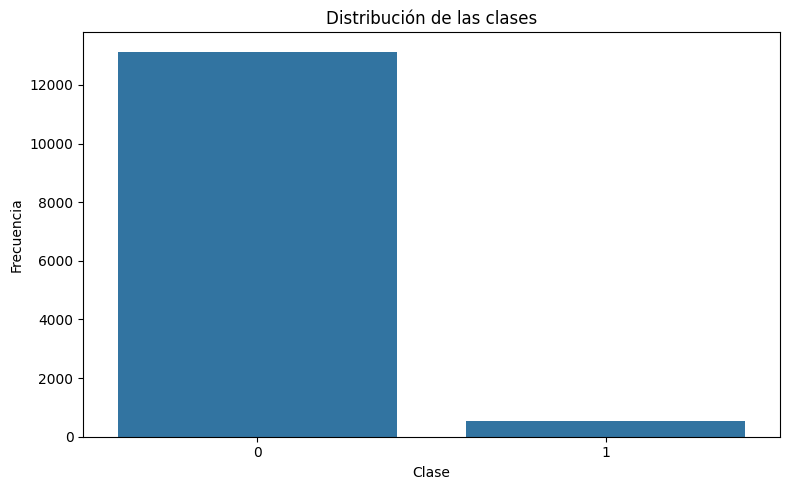

In [10]:
# Crear diagrama de barras para visualizar el balance de clases
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=df['label'], order=conteo_clases.index)

plt.title('Distribución de las clases')
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

**Observaciones:** Los atributos predictivos presentan una cardinalidad elevada, ya que contienen una gran variedad de valores numéricos distintos. Por otra parte, la variable objetivo tiene una cardinalidad de 2, correspondiente a las clases 0 y 1.

En cuanto a la distribución de las clases, se identificó un desbalance significativo: la clase 0 cuenta con 13,137 registros, mientras que la clase 1 tiene únicamente 520 registros. Esto representa aproximadamente un 96.2% y un 3.8% del conjunto de datos, respectivamente.

Esta diferencia evidencia que la clase minoritaria está considerablemente subrepresentada, lo que podría provocar que un modelo de clasificación favorezca la predicción de la clase mayoritaria y tenga dificultades para identificar correctamente los registros de la clase minoritaria.

### 1.4. Análisis de escala y concentración de las variables predictivas

**Descripción:** Se realiza un análisis estadístico de las variables predictivas para identificar sus valores mínimos, máximos y medidas de dispersión. Asimismo, se utilizan diagramas de caja (boxplots), tanto de manera general como individual, para visualizar las escalas de las variables, analizar la concentración de los datos e identificar posibles valores atípicos (outliers).

In [11]:
# Obtener estadísticas descriptivas de variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
at0,13657.0,0.050084,0.071816,-0.003352,0.007080,0.023076,0.062649,0.739494
at1,13657.0,0.235635,7.678416,-0.003414,0.008842,0.026853,0.079719,625.620690
at2,13657.0,0.200262,0.580388,-8.269512,0.081962,0.158297,0.263039,59.747983
at3,13657.0,1.611981,5.473933,0.000000,0.913588,1.306117,1.874662,620.000000
at4,13657.0,0.319739,0.200832,0.000000,0.149260,0.288131,0.454811,1.000000
at5,13657.0,0.897831,30.000541,0.000000,0.232444,0.327080,0.467606,3296.157360
at6,13657.0,0.083187,0.108721,-1.673545,0.047968,0.084757,0.123524,2.273654
at7,13657.0,2.996536,0.516465,-3.078595,2.801465,2.905451,3.066871,11.648427
at8,13657.0,7.661252,1.558410,1.034607,6.578973,7.603814,8.721378,12.782503
at9,13657.0,0.509034,18.769499,-1227.173913,0.360798,0.525976,0.686299,1806.968599


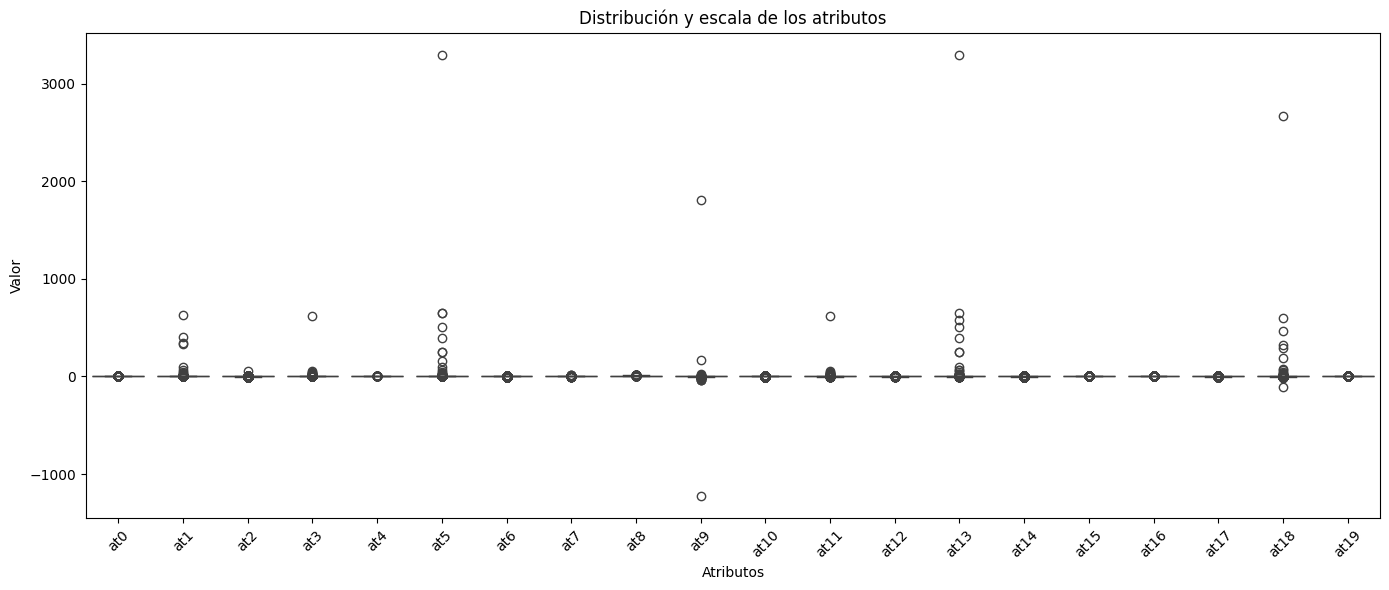

In [12]:
# Crear diagramas de caja para comparar las escalas
plt.figure(figsize=(14, 6))

sns.boxplot(data=df.drop(columns=['label']))

plt.title('Distribución y escala de los atributos')
plt.xlabel('Atributos')
plt.ylabel('Valor')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

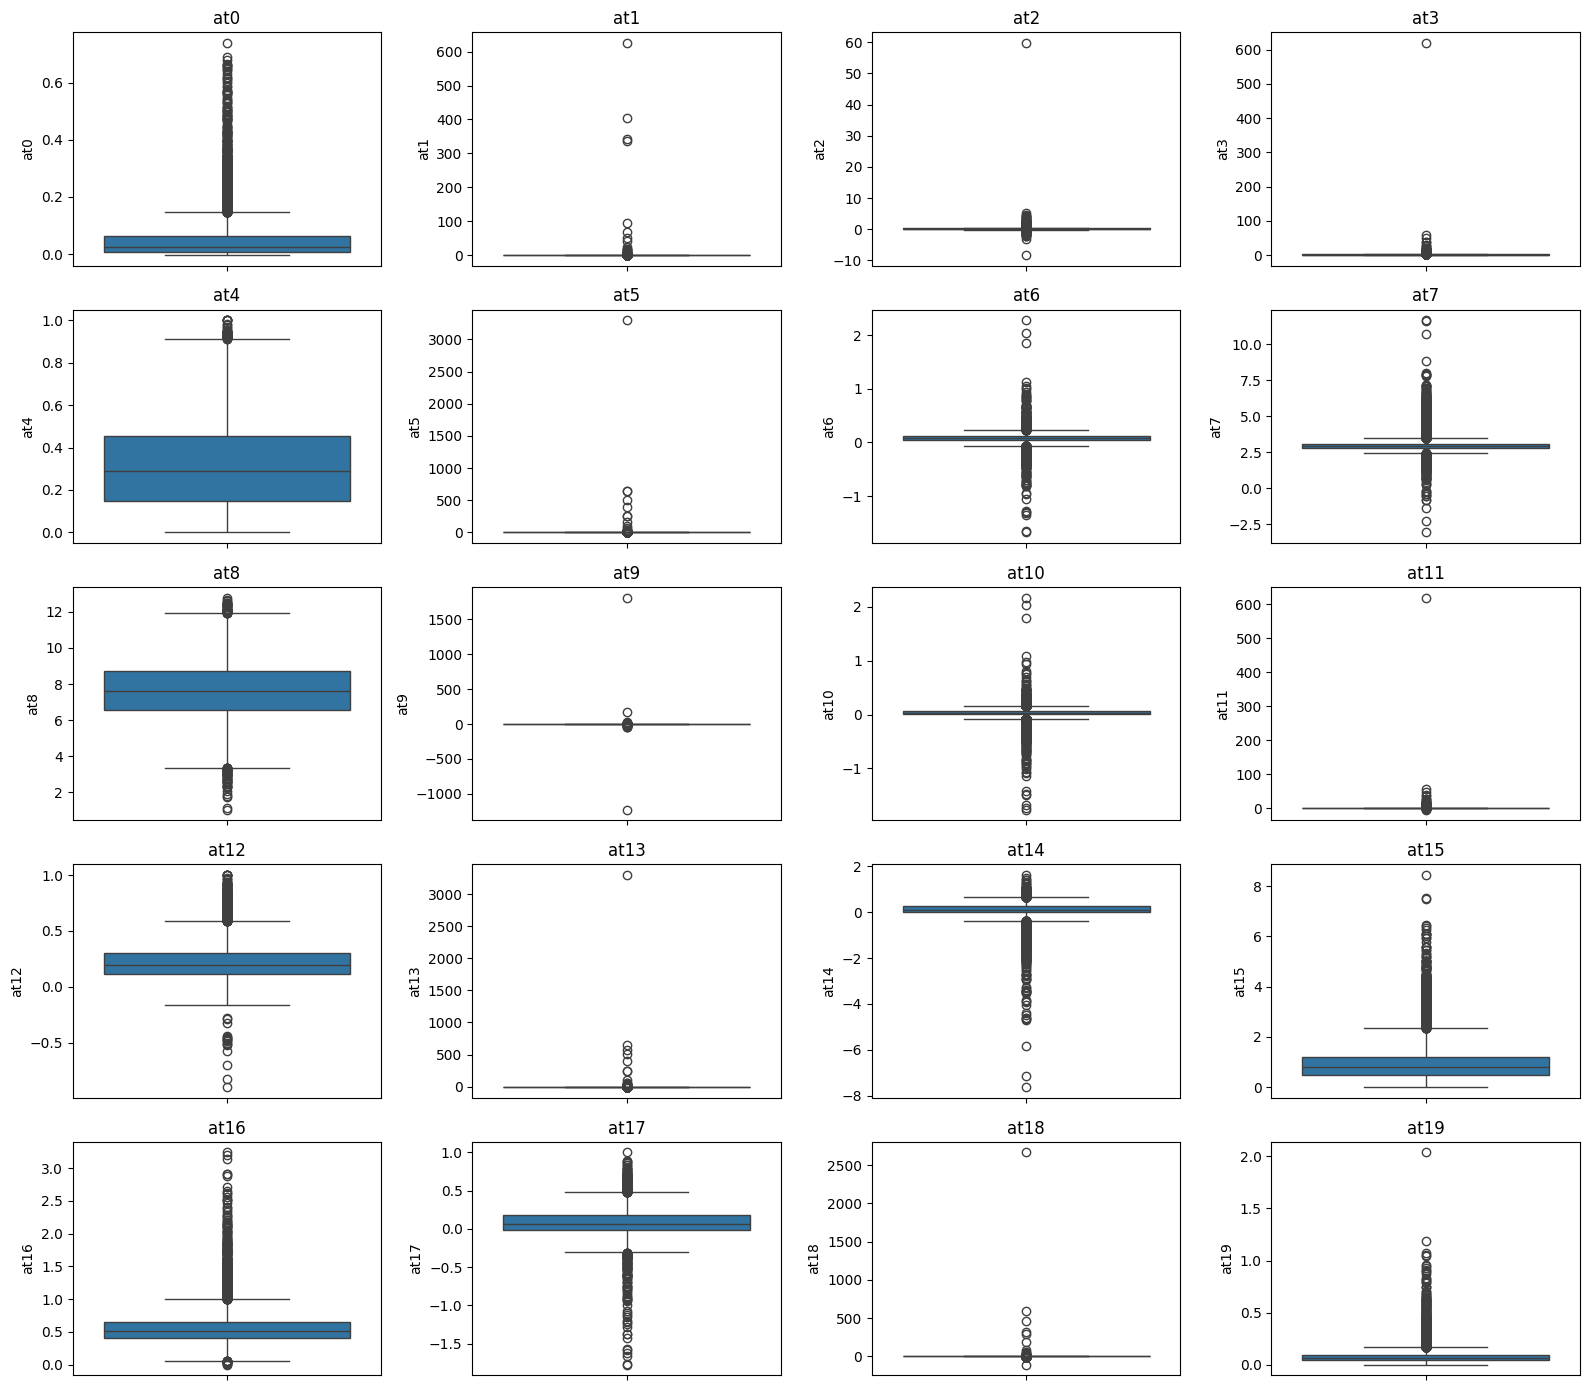

In [15]:
# Visualizar la distribución individual de cada atributo
fig, axes = plt.subplots(5, 4, figsize=(16, 14))

X = df.drop(columns=['label'])

for i, columna in enumerate(X.columns):
    sns.boxplot(y=X[columna], ax=axes[i // 4, i % 4])
    axes[i // 4, i % 4].set_title(columna)
    axes[i // 4, i % 4].set_xlabel('')

plt.tight_layout()
plt.show()

**Observaciones:** En la mayoría de las variables predictivas, los valores de la mediana se encuentran alrededor de cero. Sin embargo, se identificaron diferencias importantes en los rangos de los atributos, con valores extremos que alcanzan aproximadamente 3,296 y -1,227.

Al analizar los diagramas de caja de manera general, se observa que las diferencias de escala entre algunas variables dificultan la visualización de aquellas que presentan rangos más pequeños. Por otra parte, los diagramas individuales permiten apreciar que gran parte de las observaciones se concentra en intervalos relativamente reducidos, mientras que varios atributos presentan una cantidad considerable de valores atípicos.

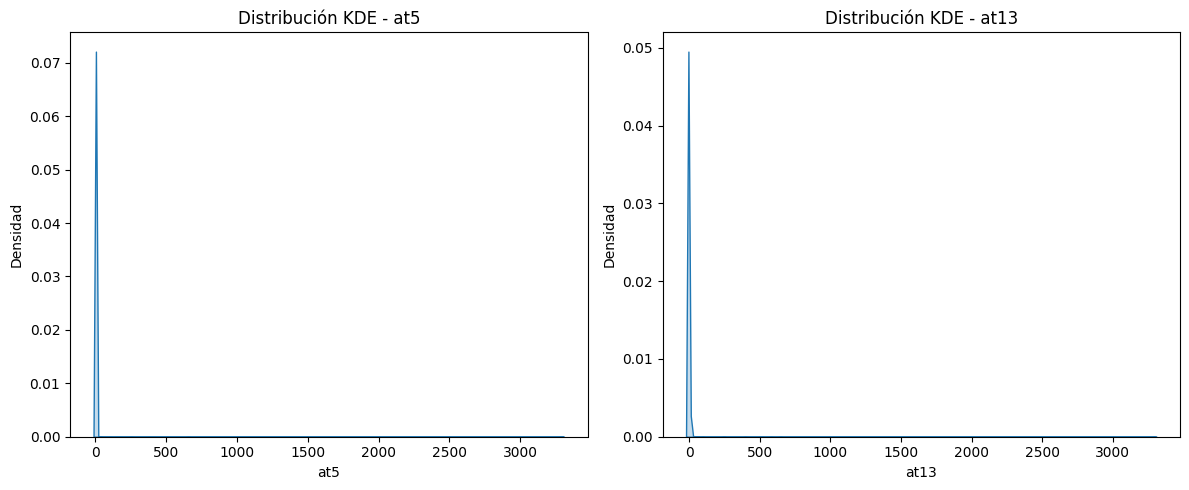

In [16]:
# Seleccionar los atributos 5 y 13
atributo_5 = df.columns[5]
atributo_13 = df.columns[13]

# Crear las gráficas KDE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=df, x=atributo_5, fill=True, ax=axes[0])
axes[0].set_title(f'Distribución KDE - {atributo_5}')
axes[0].set_xlabel(atributo_5)
axes[0].set_ylabel('Densidad')

sns.kdeplot(data=df, x=atributo_13, fill=True, ax=axes[1])
axes[1].set_title(f'Distribución KDE - {atributo_13}')
axes[1].set_xlabel(atributo_13)
axes[1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

**Observaciones:** Al analizar las distribuciones KDE de los atributos 5 y 13, se observa que la mayor concentración de los datos se encuentra en valores cercanos a cero. Sin embargo, ambas distribuciones presentan una cola pronunciada hacia la derecha, lo que evidencia una asimetría positiva considerable. También se identifican valores extremos que superan los 3,000, los cuales se alejan significativamente de la concentración principal de las observaciones.

#2. Entrenamiento del Modelo Base

**Descripción:** En este apartado se prepara el conjunto de datos para el entrenamiento del modelo de clasificación. Inicialmente, se genera una copia del conjunto de datos original y se separan las variables predictivas de la variable objetivo. Posteriormente, se configura el proceso de evaluación mediante validación cruzada estratificada de 5 particiones (StratifiedKFold).

Se define un pipeline que integra la estandarización de los datos mediante StandardScaler y un modelo de clasificación SVM con kernel RBF, utilizando sus parámetros predeterminados de configuración (C=1.0 y gamma='scale'). Finalmente, se establecen las métricas de evaluación y se ejecuta la validación cruzada para obtener los resultados del modelo base, sin aplicar ningún tratamiento al desbalance de clases.

In [17]:
#Hacer una copia del conjunto de datos
df_copy = df.copy()

# Separar los atributos (X) de la variable objetivo (y)
X = df_copy.drop(columns=['label'])
y = df_copy['label']

# Definir validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [19]:
# Definir el pipeline del modelo base
modelo_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# Definir métricas de evaluación
scoring = {
    'accuracy': 'accuracy',
    'precision_macro': make_scorer(
        precision_score,
        average='macro',
        zero_division=0
    ),
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro'
}

# Evaluar el modelo mediante validación cruzada
scores_baseline = cross_validate(
    modelo_baseline,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Obtener predicciones de validación cruzada
y_pred_baseline = cross_val_predict(
    modelo_baseline,
    X,
    y,
    cv=cv
)

In [20]:
# Diccionario para almacenar los resultados
resultados = {}

# Guardar las métricas promedio y su desviación estándar
resultados['Baseline'] = {
    'Accuracy': scores_baseline['test_accuracy'].mean(),
    'Accuracy_std': scores_baseline['test_accuracy'].std(),

    'Precision': scores_baseline['test_precision_macro'].mean(),
    'Precision_std': scores_baseline['test_precision_macro'].std(),

    'Recall': scores_baseline['test_recall_macro'].mean(),
    'Recall_std': scores_baseline['test_recall_macro'].std(),

    'F1-score': scores_baseline['test_f1_macro'].mean(),
    'F1-score_std': scores_baseline['test_f1_macro'].std(),

    'Predicciones': y_pred_baseline
}

# Mostrar métricas
print('===== Resultados: Baseline =====')

for metrica in scoring:
    valores = scores_baseline[f'test_{metrica}']
    print(f'{metrica}: {valores.mean():.4f} +/- {valores.std():.4f}')

# Mostrar matriz de confusión
print('\nMatriz de confusión:')
print(confusion_matrix(y, y_pred_baseline))

# Mostrar reporte de clasificación
print('\nReporte de clasificación:')
print(classification_report(y, y_pred_baseline))

===== Resultados: Baseline =====
accuracy: 0.9622 +/- 0.0003
precision_macro: 0.7811 +/- 0.2451
recall_macro: 0.5038 +/- 0.0036
f1_macro: 0.4980 +/- 0.0071

Matriz de confusión:
[[13137     0]
 [  516     4]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     13137
           1       1.00      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.98      0.50      0.50     13657
weighted avg       0.96      0.96      0.94     13657



**Observaciones:** El modelo baseline obtuvo un Accuracy promedio de **96.22%** durante la validación cruzada, lo que inicialmente podría interpretarse como un desempeño satisfactorio. Sin embargo, al analizar las métricas complementarias y la matriz de confusión, se observa que el modelo presenta dificultades significativas para identificar la clase minoritaria.

De los 520 registros pertenecientes a la clase 1, únicamente 4 fueron clasificados correctamente, mientras que los 516 restantes fueron identificados erróneamente como clase 0. Esto representa un Recall de apenas **0.77%** para la clase minoritaria, en contraste con el **100%** obtenido para la clase mayoritaria.

# 3. Tratamiento de Clases No Balanceadas

**Descripción:** En este apartado se definen y aplican dos técnicas de tratamiento de clases no balanceadas: SMOTEENN y One-Sided Selection (OSS), con el propósito de reducir el impacto del desbalance identificado durante el análisis exploratorio.

Ambos métodos se incorporan al pipeline de entrenamiento y se aplican únicamente sobre los datos de entrenamiento de cada partición de la validación cruzada. Finalmente, se calcula e imprime la distribución de clases resultante para cada método, con el objetivo de observar cómo modifica cada técnica la composición del conjunto de entrenamiento.

In [86]:
# Definir los métodos que vamos a comparar
metodos = {
    'SMOTEENN': SMOTEENN(random_state=42),
    'One-Sided Selection': OneSidedSelection(random_state=42)
}

In [87]:
# Revisar la distribución de clases después del balanceo
for nombre, metodo in metodos.items():

    print(f'\n===== Distribución: {nombre} =====')

    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):

        # Obtener únicamente los datos de entrenamiento de la partición
        X_fold = X.iloc[train_idx]
        y_fold = y.iloc[train_idx]

        # Escalar utilizando solamente los datos de entrenamiento
        scaler = StandardScaler()
        X_fold_scaled = scaler.fit_transform(X_fold)

        # Aplicar el método de balanceo
        X_resampled, y_resampled = metodo.fit_resample(
            X_fold_scaled,
            y_fold
        )

        # Mostrar distribución resultante
        print(f'\nPartición {fold}:')
        print(pd.Series(y_resampled).value_counts().sort_index())


===== Distribución: SMOTEENN =====

Partición 1:
label
0     9341
1    10470
Name: count, dtype: int64

Partición 2:
label
0     9407
1    10495
Name: count, dtype: int64

Partición 3:
label
0     9393
1    10492
Name: count, dtype: int64

Partición 4:
label
0     9363
1    10480
Name: count, dtype: int64

Partición 5:
label
0     9381
1    10490
Name: count, dtype: int64

===== Distribución: One-Sided Selection =====

Partición 1:
label
0    10427
1      416
Name: count, dtype: int64

Partición 2:
label
0    10424
1      416
Name: count, dtype: int64

Partición 3:
label
0    10434
1      416
Name: count, dtype: int64

Partición 4:
label
0    10440
1      416
Name: count, dtype: int64

Partición 5:
label
0    10409
1      416
Name: count, dtype: int64


**Observaciones:**

Al aplicar las técnicas de balanceo se identificaron diferencias importantes en la distribución resultante de las clases.

SMOTEENN consiguió una distribución cercana al equilibrio en las cinco particiones, con aproximadamente 47% de registros de la clase 0 y 53% de la clase 1. Esto se debe a que combina la generación de observaciones sintéticas para la clase minoritaria mediante SMOTE con la eliminación de observaciones consideradas ambiguas o inconsistentes mediante ENN. Como resultado, se incrementó considerablemente el número de registros disponibles para el entrenamiento.

Por otra parte, One-Sided Selection redujo significativamente el número de observaciones de la clase mayoritaria, conservando 416 registros de la clase minoritaria en cada partición. Sin embargo, la distribución resultante continúa presentando un desbalance considerable, con aproximadamente 96% de registros de la clase 0 y 4% de la clase 1.

# 4. Entrenamiento de modelos con clases balanceadas (Smoteenn y One-Sided Selection)

**Descripción:** En este apartado se construyen los pipelines correspondientes a los dos métodos de tratamiento de clases no balanceadas: SMOTEENN y One-Sided Selection. Cada pipeline integra la estandarización de los atributos mediante StandardScaler, la técnica de balanceo correspondiente y el clasificador SVM con kernel RBF.

Posteriormente, ambos modelos se entrenan y evalúan mediante validación cruzada estratificada de cinco particiones (StratifiedKFold), utilizando las mismas métricas de evaluación que en el modelo baseline: Accuracy, Precision, Recall y F1-score.

In [88]:
# Crear pipeline con SMOTEENN
modelo_smoteenn = ImbPipeline([
    ('scaler', StandardScaler()),
    ('balance', SMOTEENN(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# Evaluar utilizando validación cruzada
scores_smoteenn = cross_validate(
    modelo_smoteenn,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Obtener predicciones de validación cruzada
y_pred_smoteenn = cross_val_predict(
    modelo_smoteenn,
    X,
    y,
    cv=cv
)

# Guardar resultados
resultados['SMOTEENN'] = {
    'Accuracy': scores_smoteenn['test_accuracy'].mean(),
    'Accuracy_std': scores_smoteenn['test_accuracy'].std(),

    'Precision': scores_smoteenn['test_precision_macro'].mean(),
    'Precision_std': scores_smoteenn['test_precision_macro'].std(),

    'Recall': scores_smoteenn['test_recall_macro'].mean(),
    'Recall_std': scores_smoteenn['test_recall_macro'].std(),

    'F1-score': scores_smoteenn['test_f1_macro'].mean(),
    'F1-score_std': scores_smoteenn['test_f1_macro'].std(),

    'Predicciones': y_pred_smoteenn
}

# Mostrar resultados
print('===== Resultados: SMOTEENN =====')

for metrica in scoring:
    valores = scores_smoteenn[f'test_{metrica}']
    print(f'{metrica}: {valores.mean():.4f} +/- {valores.std():.4f}')

print('\nMatriz de confusión:')
print(confusion_matrix(y, y_pred_smoteenn))

print('\nReporte de clasificación:')
print(classification_report(y, y_pred_smoteenn))

===== Resultados: SMOTEENN =====
accuracy: 0.8112 +/- 0.0044
precision_macro: 0.5671 +/- 0.0057
recall_macro: 0.8058 +/- 0.0259
f1_macro: 0.5680 +/- 0.0088

Matriz de confusión:
[[10662  2475]
 [  104   416]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.81      0.89     13137
           1       0.14      0.80      0.24       520

    accuracy                           0.81     13657
   macro avg       0.57      0.81      0.57     13657
weighted avg       0.96      0.81      0.87     13657



In [89]:
# Crear pipeline con One-Sided Selection
modelo_oss = ImbPipeline([
    ('scaler', StandardScaler()),
    ('balance', OneSidedSelection(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# Evaluar utilizando validación cruzada
scores_oss = cross_validate(
    modelo_oss,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Obtener predicciones de validación cruzada
y_pred_oss = cross_val_predict(
    modelo_oss,
    X,
    y,
    cv=cv
)

# Guardar resultados
resultados['One-Sided Selection'] = {
    'Accuracy': scores_oss['test_accuracy'].mean(),
    'Accuracy_std': scores_oss['test_accuracy'].std(),

    'Precision': scores_oss['test_precision_macro'].mean(),
    'Precision_std': scores_oss['test_precision_macro'].std(),

    'Recall': scores_oss['test_recall_macro'].mean(),
    'Recall_std': scores_oss['test_recall_macro'].std(),

    'F1-score': scores_oss['test_f1_macro'].mean(),
    'F1-score_std': scores_oss['test_f1_macro'].std(),

    'Predicciones': y_pred_oss
}

# Mostrar resultados
print('===== Resultados: One-Sided Selection =====')

for metrica in scoring:
    valores = scores_oss[f'test_{metrica}']
    print(f'{metrica}: {valores.mean():.4f} +/- {valores.std():.4f}')

print('\nMatriz de confusión:')
print(confusion_matrix(y, y_pred_oss))

print('\nReporte de clasificación:')
print(classification_report(y, y_pred_oss))

===== Resultados: One-Sided Selection =====
accuracy: 0.9622 +/- 0.0001
precision_macro: 0.8978 +/- 0.1054
recall_macro: 0.5057 +/- 0.0019
f1_macro: 0.5017 +/- 0.0037

Matriz de confusión:
[[13135     2]
 [  514     6]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     13137
           1       0.75      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.86      0.51      0.50     13657
weighted avg       0.95      0.96      0.94     13657



**Observaciones:** El modelo SMOTEENN obtuvo un Accuracy de 81.12%, un Recall macro de 80.58% y un F1-score macro de 56.80%. Su principal mejora se observa en la identificación de la clase minoritaria, logrando clasificar correctamente 416 de los 520 registros positivos, equivalente a un Recall del 80%. Sin embargo, esta mejora también provocó un incremento considerable de falsos positivos, con 2,475 registros de la clase mayoritaria clasificados incorrectamente como positivos, lo que redujo la Precision de esta última clase a 14% para la clase positiva.

Por otra parte, One-Sided Selection obtuvo un Accuracy de 96.22%, un Recall macro de 50.57% y un F1-score macro de 50.17%, resultados muy similares a los del modelo baseline. Aunque presentó una Precision del 75% para la clase minoritaria, solamente identificó correctamente 6 de los 520 registros positivos, por lo que su capacidad de detección continúa siendo muy limitada.

# 5. Comparar resultados de los tres modelos

**Descripción**: La comparación de los tres modelos permite identificar que el tratamiento de clases no balanceadas modifica significativamente su comportamiento.

In [90]:
# Crear DataFrame con los resultados de los tres modelos
df_metricas = pd.DataFrame(resultados).T

# Eliminar las predicciones para mostrar solamente las métricas
df_metricas = df_metricas.drop(
    columns=['Predicciones'],
    errors='ignore'
)

display(df_metricas.round(4))

,Accuracy,Accuracy_std,Precision,Precision_std,Recall,Recall_std,F1-score,F1-score_std
Baseline,0.962217,0.000268,0.781103,0.245061,0.503846,0.003598,0.497953,0.007136
SMOTEENN,0.811159,0.004447,0.567125,0.005711,0.8058,0.025908,0.568019,0.008816
One-Sided Selection,0.962217,0.000142,0.897837,0.105384,0.505693,0.001867,0.501708,0.003684


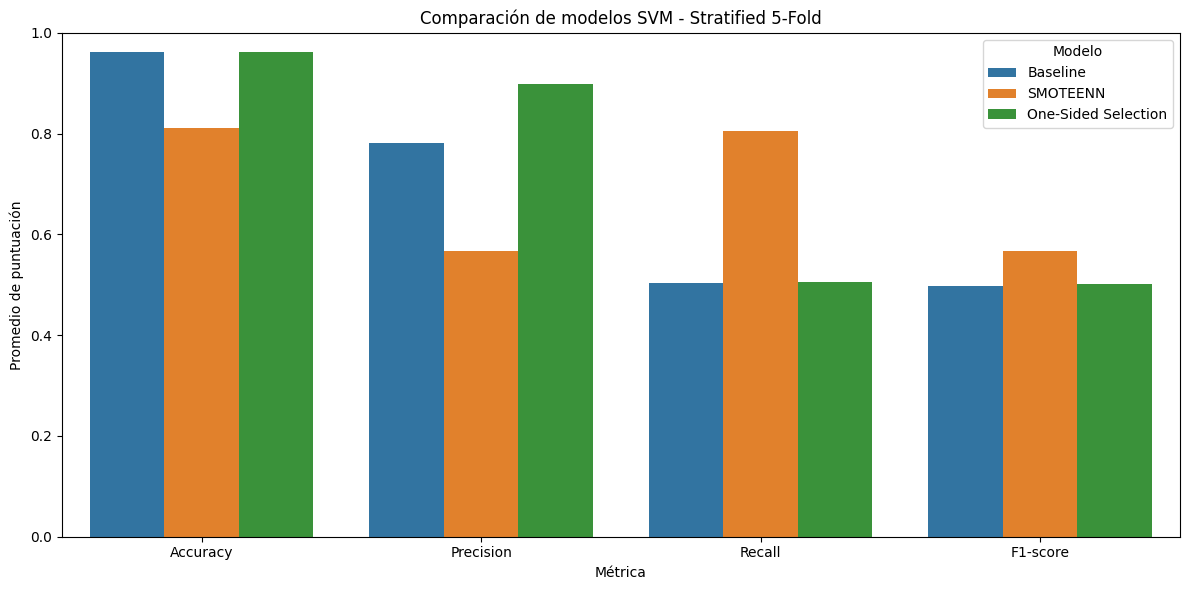

In [91]:
# Seleccionar las métricas principales
df_grafica = df_metricas[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].reset_index().melt(
    id_vars='index',
    var_name='Métrica',
    value_name='Resultado'
)

df_grafica.rename(
    columns={'index': 'Modelo'},
    inplace=True
)

# Crear gráfica comparativa
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_grafica,
    x='Métrica',
    y='Resultado',
    hue='Modelo'
)

plt.title('Comparación de modelos SVM - Stratified 5-Fold')
plt.xlabel('Métrica')
plt.ylabel('Promedio de puntuación')
plt.ylim(0, 1)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

**Conclusiones:** El modelo baseline y One-Sided Selection presentan resultados muy similares, manteniendo un Accuracy de aproximadamente 96.22%. Sin embargo, ambos muestran una capacidad muy limitada para identificar la clase minoritaria, con un Recall de 0.77% y 1.15%, respectivamente.

Por otra parte, SMOTEENN presenta una reducción en Accuracy, alcanzando 81.12%, pero consigue incrementar considerablemente el Recall macro hasta 80.58%, frente al 50.38% del baseline y el 50.57% de One-Sided Selection. También obtiene el F1-score macro más alto, con 56.80%.

Estos resultados muestran que SMOTEENN ofrece una mejora importante en la identificación de la clase minoritaria, aunque genera un mayor número de falsos positivos y reduce la precisión de las predicciones positivas. Por lo tanto, la comparación evidencia que un Accuracy elevado no necesariamente representa un mejor modelo cuando existe un desbalance significativo entre las clases.